In [3]:


df = pd.read_csv("/Users/ailinzhang/Downloads/Supplementary_Data_15_Integrated_Phenotypic_Measurements.csv")
print(df.shape)

print(df.columns.tolist())

(244000, 103)
['Unnamed: 0', 'seed', 'combi', 'rep', 'gs.sequence', 'ds.cdsCAI', 'ds.utrCdsStructureMFE', 'ds.fivepCdsStructureMFE', 'ds.threepCdsStructureMFE', 'ds.cdsBottleneckPosition', 'ds.cdsBottleneckRelativeStrength', 'ds.cdsNucleotideContentAT', 'ds.cdsHydropathyIndex', 'gs.cdsCAI', 'gs.utrCdsStructureMFE', 'gs.fivepCdsStructureMFE', 'gs.threepCdsStructureMFE', 'gs.cdsBottleneckPosition', 'gs.cdsBottleneckRelativeStrength', 'gs.cdsNucleotideContentAT', 'gs.cdsHydropathyIndex', 'group', 'log.prot.pilot.mean', 'log.prot.pilot.sd', 'log.prot.repOne', 'log.prot.repTwo', 'log.prot.repThree', 'log.prot.repFour', 'clean.lin.prot.repOne', 'clean.lin.prot.repTwo', 'clean.lin.prot.repThree', 'clean.lin.prot.repFour', 'clean.lin.prot.mean', 'clean.lin.prot.var', 'log.prot.acf.pilot.mean', 'log.prot.acf.pilot.sd', 'log.prot.acf.repOne', 'log.prot.acf.repTwo', 'log.prot.acf.repThree', 'log.prot.acf.repFour', 'clean.lin.prot.acf.repOne', 'clean.lin.prot.acf.repTwo', 'clean.lin.prot.acf.repTh

In [4]:
import pandas as pd
df = pd.read_csv("../data/E.Coli_proteins.csv")
print(df.shape)

print(df.columns.tolist())
print(df.head())

(6348, 4)
['Sequence', 'Value', 'Dataset', 'Split']
                                            Sequence  Value          Dataset  \
0  AUGCCUGCGCCUGACUUAUUGACUGCCGAGCUAACGCUGACCGGCC...      0  E.Coli proteins   
1  AUGAGCUCGCCCACCACCACAAUCGAUCCCCAACUCGCCCGUUGGG...      0  E.Coli proteins   
2  AUGCUGAGUAAAGGACGCCGUCACCUCGCUAUGAGGCUCGACGACG...      2  E.Coli proteins   
3  AUGCGCACAACGUCGGCACGAACCAAAGCCACCGCCAACGGACAGC...      0  E.Coli proteins   
4  AUGGACGUUUUUGCCACCGGUGCCGGGCAGGUGGAUCCUGCGAAGG...      0  E.Coli proteins   

   Split  
0  train  
1  train  
2  train  
3  train  
4  train  


In [6]:
import pandas as pd

# 读数据
df = pd.read_csv("../data/Supplementary_Data_15_Integrated_Phenotypic_Measurements.csv")

print("=" * 60)
print("SHAPE")

print("=" * 60)
print(df.shape)

print("\n")

# ======================
# 看几个关键列
# ======================

cols = [
    "gs.sequence",
    "log.prot.pilot.mean",
    "clean.lin.prot.mean",
    "log.prot.repOne",
    "log.prot.repTwo",
    "log.prot.repThree",
    "log.prot.repFour",
]

print("=" * 60)
print("NON-NA COUNTS")
print("=" * 60)
print(df[cols].notna().sum())

print("\n")

# ======================
# summary
# ======================

print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(
    df[
        [
            "log.prot.pilot.mean",
            "clean.lin.prot.mean",
        ]
    ].describe()
)

print("\n")

# ======================
# 同时有两个label的数据
# ======================

subset = df[
    [
        "log.prot.pilot.mean",
        "clean.lin.prot.mean",
    ]
].dropna()

print("=" * 60)
print("ROWS WITH BOTH LABELS")
print("=" * 60)
print(subset.shape)

print("\n")

print("=" * 60)
print("CORRELATION")
print("=" * 60)
print(subset.corr())

print("\n")

# ======================
# 看看sequence长啥样
# ======================

print("=" * 60)
print("FIRST 5 SEQUENCES")
print("=" * 60)

for i in range(5):
    seq = df["gs.sequence"].iloc[i]
    print(f"\nSequence {i}")
    print(seq[:200])

print("\n")

# ======================
# 长度分布
# ======================

seq_lengths = df["gs.sequence"].dropna().astype(str).str.len()

print("=" * 60)
print("SEQUENCE LENGTH")
print("=" * 60)
print(seq_lengths.describe())

SHAPE
(244000, 103)


NON-NA COUNTS
gs.sequence            244000
log.prot.pilot.mean       310
clean.lin.prot.mean    242269
log.prot.repOne        239596
log.prot.repTwo        238721
log.prot.repThree      238070
log.prot.repFour       237933
dtype: int64


SUMMARY
       log.prot.pilot.mean  clean.lin.prot.mean
count           310.000000        242269.000000
mean              1.191231            49.881106
std               0.579224            26.468058
min              -0.004370             1.000000
25%               0.810229            27.523790
50%               1.272396            48.905967
75%               1.685843            72.299709
max               2.246017           100.000000


ROWS WITH BOTH LABELS
(308, 2)


CORRELATION
                     log.prot.pilot.mean  clean.lin.prot.mean
log.prot.pilot.mean             1.000000             0.839791
clean.lin.prot.mean             0.839791             1.000000


FIRST 5 SEQUENCES

Sequence 0
tccgttggggtgtgttaccctaaatgtcggtgtt

count    242269.000000
mean         11.728831
std           2.923416
min           1.000000
25%           9.860000
50%          12.335000
75%          14.142500
max          16.000000
Name: protein_mean, dtype: float64


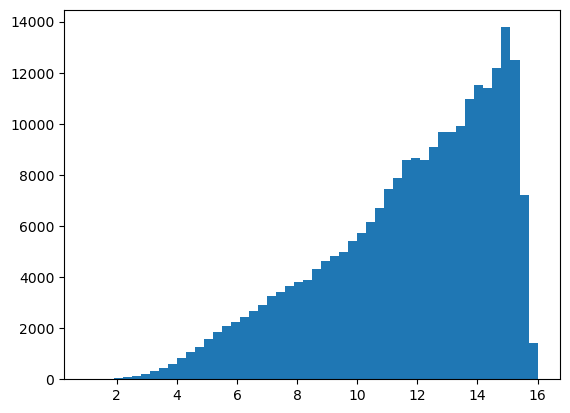

In [8]:
import matplotlib.pyplot as plt
df["protein_mean"] = df[
[
"log.prot.repOne",
"log.prot.repTwo",
"log.prot.repThree",
"log.prot.repFour"
]
].mean(axis=1)

print(
    df["protein_mean"].describe()
)
plt.hist(
    df["protein_mean"].dropna(),
    bins=50
)
plt.show()

In [9]:
print(
df[
[
"log.prot.repOne",
"log.prot.repTwo",
"log.prot.repThree",
"log.prot.repFour"
]
].corr()
)

                   log.prot.repOne  log.prot.repTwo  log.prot.repThree  \
log.prot.repOne           1.000000         0.956469           0.934556   
log.prot.repTwo           0.956469         1.000000           0.947201   
log.prot.repThree         0.934556         0.947201           1.000000   
log.prot.repFour          0.932149         0.946964           0.929410   

                   log.prot.repFour  
log.prot.repOne            0.932149  
log.prot.repTwo            0.946964  
log.prot.repThree          0.929410  
log.prot.repFour           1.000000  


In [10]:
sample_seq = df["gs.sequence"].iloc[0]

for i in range(len(sample_seq)-2):
    if sample_seq[i:i+3] == "atg":
        print(i)

23
46
58


In [11]:
seq = df["gs.sequence"].iloc[0]
start = seq.find("atg")

cds = seq[start:]

codons = [
    cds[i:i+3]
    for i in range(0, len(cds)-len(cds)%3, 3)
]

print(codons[:20])

['atg', 'tcg', 'gtg', 'ttc', 'tga', 'gcg', 'cta', 'cga', 'tgc', 'tca', 'gta', 'tta', 'tga', 'tct', 'tag', 'gac', 'taa', 'gcc', 'cca', 'gat']


In [12]:
[c for c in df.columns if "sequence" in c.lower() or "cds" in c.lower()]

['gs.sequence',
 'ds.cdsCAI',
 'ds.utrCdsStructureMFE',
 'ds.fivepCdsStructureMFE',
 'ds.threepCdsStructureMFE',
 'ds.cdsBottleneckPosition',
 'ds.cdsBottleneckRelativeStrength',
 'ds.cdsNucleotideContentAT',
 'ds.cdsHydropathyIndex',
 'gs.cdsCAI',
 'gs.utrCdsStructureMFE',
 'gs.fivepCdsStructureMFE',
 'gs.threepCdsStructureMFE',
 'gs.cdsBottleneckPosition',
 'gs.cdsBottleneckRelativeStrength',
 'gs.cdsNucleotideContentAT',
 'gs.cdsHydropathyIndex']

In [13]:
feature_cols = [
    "gs.cdsCAI",
    "gs.utrCdsStructureMFE",
    "gs.fivepCdsStructureMFE",
    "gs.threepCdsStructureMFE",
    "gs.cdsBottleneckPosition",
    "gs.cdsBottleneckRelativeStrength",
    "gs.cdsNucleotideContentAT",
    "gs.cdsHydropathyIndex",
]

In [14]:
data = df[
    feature_cols + ["protein_mean"]
].dropna()

print(data.shape)

(242269, 9)


In [15]:
from sklearn.model_selection import train_test_split

X = data[feature_cols]
y = data["protein_mean"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from scipy.stats import spearmanr
import numpy as np

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

r2 = r2_score(y_test, pred)
spearman = spearmanr(y_test, pred).correlation

rmse = np.sqrt(
    np.mean((y_test - pred) ** 2)
)

print("R2 =", r2)
print("Spearman =", spearman)
print("RMSE =", rmse)

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
R2 = 0.30004286564867344
Spearman = 0.5385920395137186
RMSE = 2.4535507952014695


In [17]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1,
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)

print(
    "RF R2 =",
    r2_score(y_test, pred_rf)
)

print(
    "RF Spearman =",
    spearmanr(y_test, pred_rf).correlation
)

RF R2 = 0.36586844231897
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
RF Spearman = 0.582413235470926


In [18]:
import pandas as pd

importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf.feature_importances_
})

print(
    importance_df.sort_values(
        "importance",
        ascending=False
    )
)

                            feature  importance
1             gs.utrCdsStructureMFE    0.735500
2           gs.fivepCdsStructureMFE    0.081312
6         gs.cdsNucleotideContentAT    0.059867
3          gs.threepCdsStructureMFE    0.036113
7             gs.cdsHydropathyIndex    0.032796
5  gs.cdsBottleneckRelativeStrength    0.019904
4          gs.cdsBottleneckPosition    0.017590
0                         gs.cdsCAI    0.016917


analyze_kmer_coefficients

In [5]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

COEF_PATH = PROJECT_ROOT / "k8_mfe_coefficients.csv"
coef_df = pd.read_csv(COEF_PATH)

def gc_content(seq):
    return (seq.count("G") + seq.count("C")) / len(seq)

for base in "ATGC":
    coef_df[f"{base}_frac"] = coef_df["kmer"].apply(
        lambda x: x.count(base) / len(x)
    )

coef_df["gc"] = coef_df["kmer"].apply(gc_content)

top_pos = coef_df.sort_values("coef", ascending=False).head(20)
top_neg = coef_df.sort_values("coef", ascending=True).head(20)

print("\nTop positive k-mers:")
print(top_pos[["kmer", "coef", "gc", "A_frac", "T_frac", "G_frac", "C_frac"]])

print("\nTop negative k-mers:")
print(top_neg[["kmer", "coef", "gc", "A_frac", "T_frac", "G_frac", "C_frac"]])

print("\nAverage composition:")
print("Positive:")
print(top_pos[["gc", "A_frac", "T_frac", "G_frac", "C_frac"]].mean())

print("\nNegative:")
print(top_neg[["gc", "A_frac", "T_frac", "G_frac", "C_frac"]].mean())


Top positive k-mers:
         kmer      coef     gc  A_frac  T_frac  G_frac  C_frac
2    GTTCGTTG  4.138594  0.500   0.000   0.500   0.375   0.125
25   AATGCAAG  2.922238  0.375   0.500   0.125   0.250   0.125
32   AAATGCAA  2.836111  0.250   0.625   0.125   0.125   0.125
50   AGTTCAAC  2.639094  0.375   0.375   0.250   0.125   0.250
55   TTCAGTTC  2.625824  0.375   0.125   0.500   0.125   0.250
66   GAAATGCA  2.538722  0.375   0.500   0.125   0.250   0.125
83   TCGTTGCG  2.362898  0.625   0.000   0.375   0.375   0.250
84   TACGTACA  2.360052  0.375   0.375   0.250   0.125   0.250
89   AGTGTTTG  2.325585  0.375   0.125   0.500   0.375   0.000
90   TTCGTTGC  2.322188  0.500   0.000   0.500   0.250   0.250
92   TTCATGCA  2.312130  0.375   0.250   0.375   0.125   0.250
93   AAGTTCAA  2.307429  0.250   0.500   0.250   0.125   0.125
95   TTCTGTTC  2.301461  0.375   0.000   0.625   0.125   0.250
101  TACGTTCA  2.273825  0.375   0.250   0.375   0.125   0.250
105  GTTCTTAA  2.251639  0.250   